# Student Burnout Risk Detection

Academic institutions increasingly face high rates of student burnout, driven by heavy course loads, sleep deprivation, excessive screen time, and psychological stress.

we addresses this by providing a deployable end-to-end classification pipeline to flag students at high risk before they reach a breaking point.

## Data preparation

This project uses the University Student Stress Dataset from Mendeley Data ([DOI: 10.17632/rc5htd5dfr.1](https://data.mendeley.com/datasets/rc5htd5dfr/1)), specifically the `Raw_Responses` directory ([Direct File Link](https://data.mendeley.com/datasets/rc5htd5dfr/1/files/02e68a9a-6e92-425a-bc76-5a218eaf7b45)).

A copy of the raw dataset is committed under https://github.com/speedyk-005/burnout-predict/tree/main/data/raw to ensure offline execution and end-to-end training reproducibility.

In [235]:
!wget -O university_student_stress.csv https://raw.githubusercontent.com/speedyk-005/burnout-predict/main/data/raw/university_student_stress.csv

--2026-11-05 22:51:28--  https://raw.githubusercontent.com/speedyk-005/burnout-predict/main/data/raw/university_student_stress.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 300647 (294K) [application/octet-stream]
Saving to: ‘university_student_stress.csv’

university_student_ 100%[===================>] 293.60K  --.-KB/s    in 0.02s   

2026-11-05 22:51:28 (14.6 MB/s) - ‘university_student_stress.csv’ saved [300647/300647]



In [236]:
!ls

pipeline.bin  sample_data  university_student_stress.csv


In [237]:
import pandas as pd

# Read the file with codec `latin1` codec to prevent decoding error
df = pd.read_csv("university_student_stress.csv", encoding="latin1")
df.head(2)

,Timestamp,1. Age\nExample: 23 [Restricted to 19ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,2. Gender\nExample: Male,3. Study_Hours (per day) \nExample: 3,4. Class_Attendance (%) \nExample: 85,5. Tuition (Private Coaching) \nExample: Yes,6. Exam_Frequency (per semester) \nExample: 4,7. Assignment_Load (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,8. Sleep_Hours (per day) \nExample: 6,9. Physical_Exercise (hours per week) \nExample: 2,10. Social_Media_Use (hours per day) \nExample: 3,11. Screen_Time (hours per day) \nExample: 6,12. Family_Income_Level \nExample: Middle,13. Peer_Pressure (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,14. Family_Support (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,15. Anxiety_Level (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½,16. University_Type \nExample: Public University,17. Stress_Score (1ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï¿½ï,18. Stress_Level \nExample: Moderate
0,2025/10/01 12:00:00 AM GMT+6,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,2025/10/01 12:36:28 AM GMT+6,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High


### Let's clean it!

In [249]:
df_clean = df.drop("Timestamp", axis=1)  # We don't need that

# The column names are so messy right now.
# Let's keep the necessary parts.
df_clean.columns = df_clean.columns.str.split().str[1].str.lower()

# Ensure age range
df_clean = df_clean[(df_clean["age"] >= 19) & (df_clean["age"] <= 24)]
df_clean.head(5)

# Normalize income, gender and university type
df_clean["gender"] = df_clean["gender"].str.lower()
df_clean["family_income_level"] = df_clean["family_income_level"].str.lower()
df_clean["university_type"] = df_clean["university_type"].str.split().str[0].str.lower()

In [250]:
df_clean.isnull().sum().sum()

np.int64(0)

In [251]:
# Let's convert the label from ternary to binary
df_clean["at_risk"] = df_clean["stress_level"].map({"Low": 0, "Medium": 1, "High": 1})
df_clean["at_risk"].head()

,at_risk
0,1
1,1
2,1
3,1
4,0


In [252]:
df_clean = df_clean.drop(
    columns=[
        "stress_level",
        "stress_score",
        "exam_frequency",  # Lacks a temporal anchor
        "anxiety_level",  # Related to stress too much
    ]
)

In [253]:
df_clean.describe()

,age,study_hours,class_attendance,assignment_load,sleep_hours,social_media_use,screen_time,peer_pressure,family_support,at_risk
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.0000,3000.000000
mean,21.517333,4.488667,68.872333,4.996000,6.519000,3.487000,5.918333,4.984000,5.0270,0.585667
std,1.705678,2.858659,17.442576,2.594654,1.687381,2.288721,3.185129,2.567478,2.5681,0.492689
min,19.000000,0.000000,40.000000,1.000000,4.000000,0.000000,1.000000,1.000000,1.0000,0.000000
25%,20.000000,2.000000,54.000000,3.000000,5.000000,2.000000,3.000000,3.000000,3.0000,0.000000
50%,21.000000,4.000000,69.000000,5.000000,7.000000,3.000000,6.000000,5.000000,5.0000,1.000000
75%,23.000000,7.000000,84.000000,7.000000,8.000000,5.000000,9.000000,7.000000,7.0000,1.000000
max,24.000000,9.000000,99.000000,9.000000,9.000000,7.000000,11.000000,9.000000,9.0000,1.000000


In [254]:
df_clean.dtypes

,0
age,int64
gender,object
study_hours,int64
class_attendance,int64
tuition,object
assignment_load,int64
sleep_hours,int64
physical_exercise,object
social_media_use,int64
screen_time,int64


## Exploratory Data Analysis

([0, 1, 2],
 [Text(0, 0, 'national'), Text(1, 0, 'private'), Text(2, 0, 'public')])

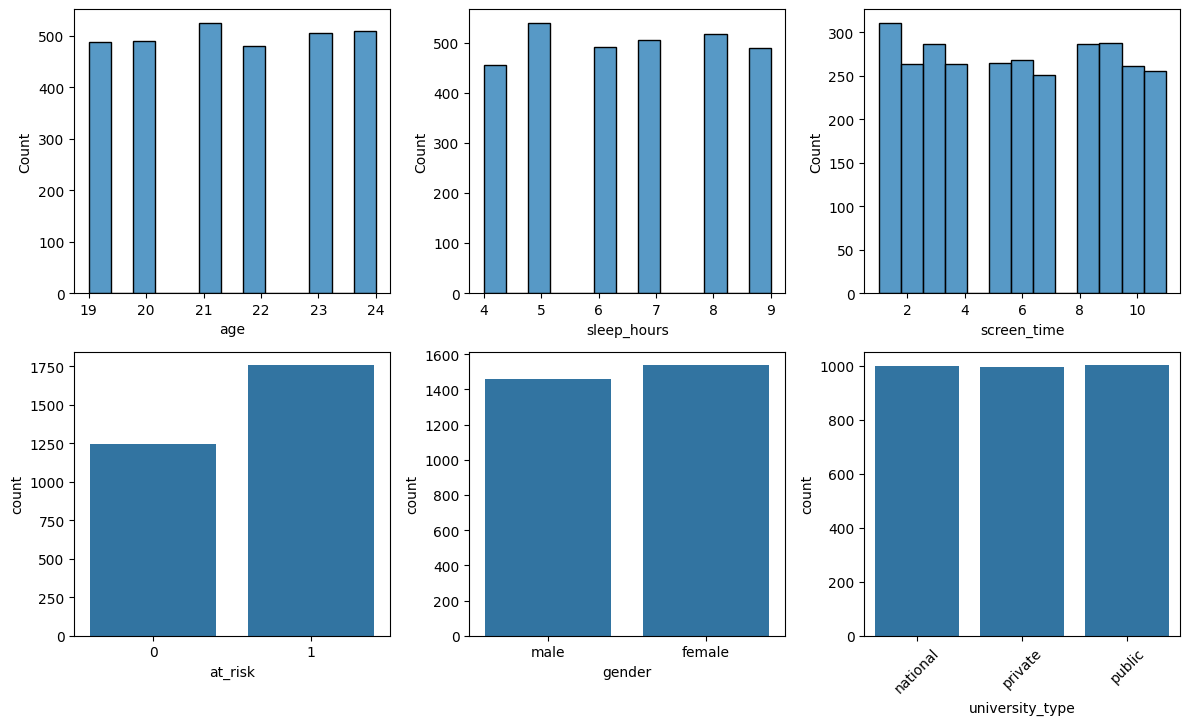

In [256]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

sns.histplot(df_clean["age"], ax=axes[0, 0])
sns.histplot(df_clean["sleep_hours"], ax=axes[0, 1])
sns.histplot(df_clean["screen_time"], ax=axes[0, 2])

sns.countplot(x="at_risk", data=df_clean, ax=axes[1, 0])
sns.countplot(x="gender", data=df_clean, ax=axes[1, 1])
sns.countplot(x="university_type", data=df_clean, ax=axes[1, 2])

plt.tight_layout()
plt.xticks(rotation=45)

<Axes: >

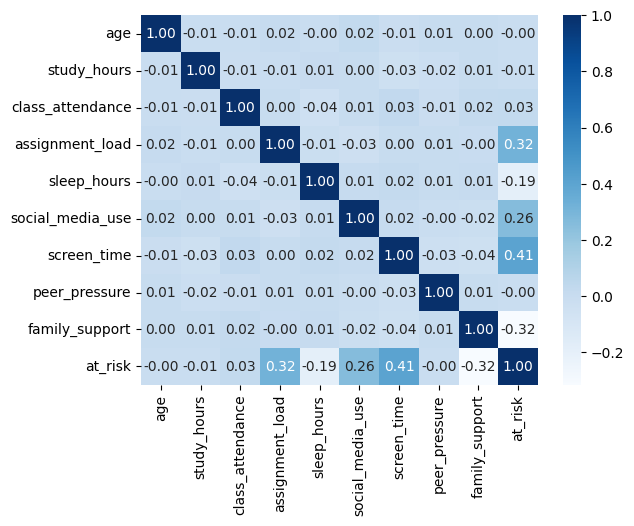

In [257]:
df_num = df_clean.select_dtypes(include=["number"])
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="Blues")

The heatmap reveals that `age` and `peer_pressure` have zero correlation with `burnout`, whereas variables like `study_hours`, and `class_attendance` have a very low linear correlation with burnout. However, human behavior is rarely strictly linear.

In [197]:
SEED = 42

In [259]:
from sklearn.model_selection import train_test_split


def train_test_dev_split(df, test_size=0.2, dev_size=0.25):
    df_full_train, df_test = train_test_split(
        df,
        test_size=test_size,
        random_state=SEED,
    )
    df_train, df_val = train_test_split(
        df_full_train,
        test_size=dev_size,
        random_state=SEED,
    )
    return df_train, df_val, df_test


df_train, df_val, df_test = train_test_dev_split(df_clean)

## Model training

In [262]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer()


def prepare_X_and_y(df, prefit=True):
    y = df["at_risk"].values
    records = df.drop("at_risk", axis=1).to_dict("records")

    if not prefit:
        X = dv.fit_transform(records)
    else:
        X = dv.transform(records)
    return X, y


X_train, y_train = prepare_X_and_y(df_train, prefit=False)
X_val, y_val = prepare_X_and_y(df_val)

### Let's start with a linear model first.

In [264]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def train_linear_model(X, y, C=1.0):
    model = LogisticRegression(
        max_iter=1000,
        random_state=SEED,
        C=C,
    )
    model.fit(X, y)
    return model


model = train_linear_model(X_train, y_train)
y_pred = model.predict(X_val)
roc_auc_score(y_val, y_pred)

np.float64(0.8458279009126467)

Let's tune C

In [269]:
C = [0.01, 0.1, 0.3, 0.5, 0.7, 1.0]
for c in C:
    model = train_linear_model(X_train, y_train, C=c)
    y_pred = model.predict(X_val)
    score = roc_auc_score(y_val, y_pred)
    print(f"{c=} -> {round(score, 3)}")

c=0.01 -> 0.843
c=0.1 -> 0.845
c=0.3 -> 0.846
c=0.5 -> 0.846
c=0.7 -> 0.846
c=1.0 -> 0.846


`>=0.3` leads to a better model

Now let's try removing the features zero correlations with `at_risk`

In [271]:
low_corr_feat = ["age", "peer_pressure"]

# Let's see if removing them to see if there are improvements
df_clean_2 = df_clean.drop(low_corr_feat, axis=1)

df_train_2, df_test_2, df_val_2 = train_test_dev_split(df_clean_2)
X_train_2, y_train_2 = prepare_X_and_y(df_train_2, prefit=False)
X_val_2, y_val_2 = prepare_X_and_y(df_val_2)

model_2 = train_linear_model(X_train_2, y_train_2, C=0.3)
y_pred_2 = model_2.predict(X_val_2)
round(roc_auc_score(y_val_2, y_pred_2), 3)

np.float64(0.828)

It is worst, let's leep them

### It is time to try some tree models

#### RandomForest

In [272]:
X_train, y_train = prepare_X_and_y(df_train, prefit=False)

In [274]:
from sklearn.ensemble import RandomForestClassifier


def train_random_forest(
    X,
    y,
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=1,
):
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=SEED,
        class_weight="balanced",
        n_jobs=-1,
    )
    model.fit(X, y)
    return model


model = train_random_forest(X_train, y_train)
y_pred = model.predict(X_val)
roc_auc_score(y_val, y_pred)

np.float64(0.821102626187372)

Let's tune some parameters

In [275]:
max_depths = [4, 6, 8, 12, None]
min_samples_leafs = [2, 5, 10, 20]

scores = []
for max_depth in max_depths:
    for min_samples_leaf in min_samples_leafs:
        model = train_random_forest(
            X_train,
            y_train,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
        )
        y_pred = model.predict(X_val)
        score = roc_auc_score(y_val, y_pred)
        scores.append((max_depth, min_samples_leaf, round(score, 3)))

<Axes: xlabel='min_samples_leaf', ylabel='max_depth'>

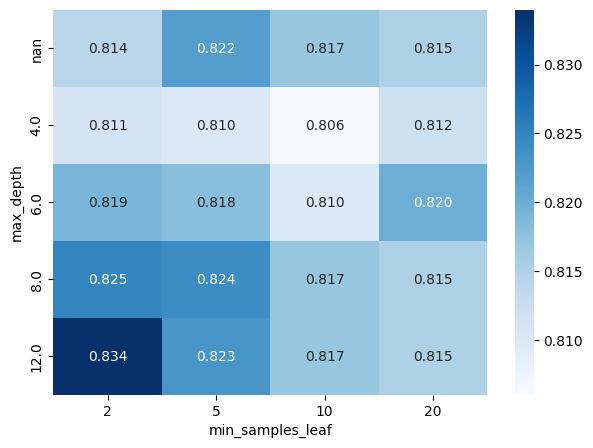

In [276]:
df_score = pd.DataFrame(scores, columns=["max_depth", "min_samples_leaf", "score"])
df_score = df_score.pivot(index="max_depth", columns="min_samples_leaf", values="score")

plt.figure(figsize=(7, 5))
sns.heatmap(df_score, annot=True, fmt=".3f", cmap="Blues")

The winner is `max_depth=12` and `min_samples_leaf=2`.

In [280]:
BEST_DEPTH = 12
BEST_MIN_SAMPLES_LEAF = 2

Now let's see where we can cap `n_estimators`

In [281]:
n_estimators = [10, 50, 100, 150, 200]

scores = []
for n_estimator in n_estimators:
    model = train_random_forest(
        X_train,
        y_train,
        n_estimators=n_estimator,
        max_depth=BEST_DEPTH,
        min_samples_leaf=BEST_MIN_SAMPLES_LEAF,
    )
    y_pred = model.predict(X_val)
    score = roc_auc_score(y_val, y_pred)
    scores.append((n_estimator, round(score, 3)))

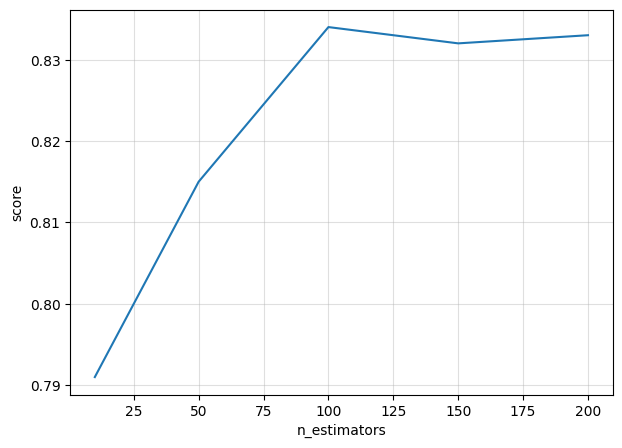

In [282]:
df_score = pd.DataFrame(scores, columns=["n_estimators", "score"])

plt.figure(figsize=(7, 5))
plt.plot(df_score["n_estimators"], df_score["score"])
plt.xlabel("n_estimators")
plt.ylabel("score")
plt.grid(True, alpha=0.4)

`100` (default) is already oaky

In [283]:
BEST_N_ESTIMATORS = 100

In [284]:
rf_model = train_random_forest(
    X_train,
    y_train,
    n_estimators=BEST_N_ESTIMATORS,
    max_depth=BEST_DEPTH,
    min_samples_leaf=BEST_MIN_SAMPLES_LEAF,
)
y_pred = rf_model.predict(X_val)
round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.834)

In [285]:
feature_names = list(dv.get_feature_names_out())
importances = rf_model.feature_importances_
sorted_importances = importances.argsort()

print("Top 5 important features")
for i in sorted_importances[:5]:
    print(f"{feature_names[i]}: {importances[i]}")

Top 5 important features
family_income_level=high: 0.009952005255392875
gender=male: 0.010506312400690467
gender=female: 0.010654177114135042
university_type=public: 0.01097223595440076
family_income_level=low: 0.011096521643154023


Radom forest has better score than linear regression (`0.834` > `0.828`)

#### Xgboost

Since the dataset is imbalanced, lets balance it for xgboost

In [286]:
pip install xgboost

In [287]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

In [299]:
xgb_params = {
    "objective": "binary:logistic",
    "min_child_weight": 2,
    "max_depth": 12,
    "eta": 0.1,
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1,
}

In [300]:
def train_xgboost(xgb_params, dtrain, evals=None):
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        verbose_eval=5,
        evals=evals,
    )
    return model


model = train_xgboost(xgb_params, dtrain)
y_pred = model.predict(dval)
round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.899)

The model is pretty good, let's see if we can get it an higher score

In [301]:
max_depths = [4, 6, 8, 12, None]
min_child_weights = [2, 5, 10, 20]

scores = []
for max_depth in max_depths:
    for min_child_weight in min_child_weights:
        xgb_params["max_depth"] = max_depth
        xgb_params["min_child_weight"] = min_child_weight

        model = train_xgboost(xgb_params, dtrain)
        y_pred = model.predict(dval)
        score = roc_auc_score(y_val, y_pred)
        scores.append((max_depth, min_child_weight, round(score, 3)))

<Axes: xlabel='min_child_weight', ylabel='max_depth'>

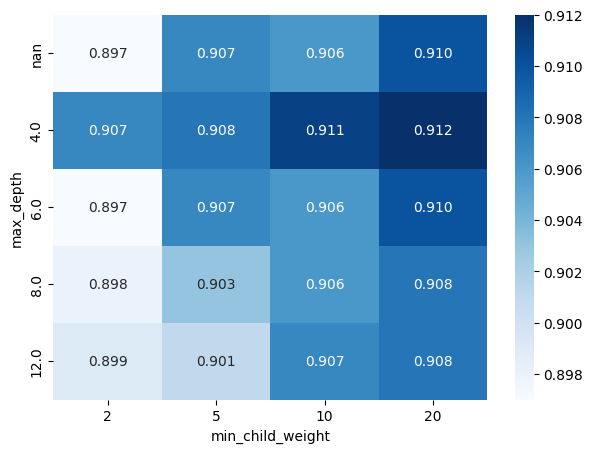

In [302]:
df_score = pd.DataFrame(scores, columns=["max_depth", "min_child_weight", "score"])
df_score = df_score.pivot(index="max_depth", columns="min_child_weight", values="score")

plt.figure(figsize=(7, 5))
sns.heatmap(df_score, annot=True, fmt=".3f", cmap="Blues")

`max_depth=4` and `min_child_weight=20` leads to slightly higher score

In [303]:
xgb_params["max_depth"] = 4
xgb_params["min_child_weight"] = 20

Now, let's see which Eta is best

In [314]:
%%capture output
watchlist = [(dtrain, "dtrain"), (dval, "dval")]
etas = [0.01, 0.04, 0.07, 0.1, 0.3, 0.5]

for eta in etas:
    xgb_params["eta"] = eta
    model = train_xgboost(xgb_params, dtrain, watchlist)
    model.predict(dval)
    print("SEPARATOR")

Let's convert the xgb ouput into df_scores

In [315]:
df_scores = []
for block in output.stdout.split("SEPARATOR"):
    block_stripped = block.strip()
    if not block_stripped:
        continue

    lines = pd.Series(block_stripped.split("\n"))
    records = lines.str.split("\t")

    df_score = pd.DataFrame.from_records(
        records,
        columns=("iter_num", "dtrain-logloss", "dval-logloss"),
    )
    df_score["iter_num"] = df_score["iter_num"].str.strip("[]").astype(int)
    df_score["dtrain-logloss"] = df_score["dtrain-logloss"].str.split(":").str[1].astype(float)
    df_score["dval-logloss"] = df_score["dval-logloss"].str.split(":").str[1].astype(float)

    df_scores.append(df_score)

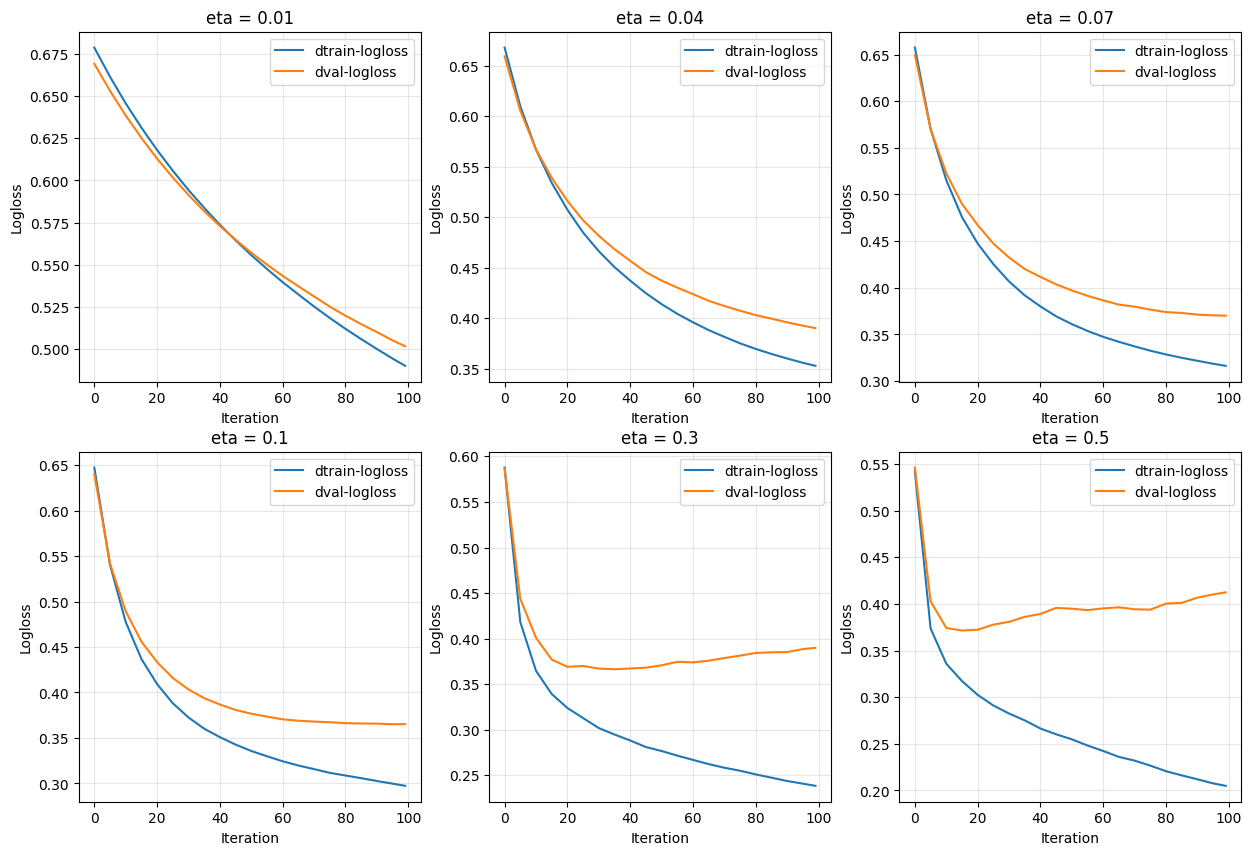

In [316]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, df_score in enumerate(df_scores):
    j, k = divmod(i, 3)
    ax = axes[j, k]

    iterations = df_score["iter_num"]
    train_loss = df_score["dtrain-logloss"]
    val_loss = df_score["dval-logloss"]

    ax.plot(iterations, train_loss, label="dtrain-logloss")
    ax.plot(iterations, val_loss, label="dval-logloss")
    ax.set_title(f"eta = {etas[i]}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Logloss")
    ax.legend()
    ax.grid(True, alpha=0.3)

`ETA=0.1` leads to a lower and stable loss (`0.301`)


In [317]:
xgb_params["eta"] = 0.1
xgb_params

{'objective': 'binary:logistic',
 'min_child_weight': 20,
 'max_depth': 4,
 'eta': 0.1,
 'nthread': 8,
 'seed': 42,
 'verbosity': 1}

In [318]:
model = train_xgboost(xgb_params, dtrain)
y_pred = model.predict(dval)

print("roc_auc_score:", round(roc_auc_score(y_val, y_pred), 3))

roc_auc_score: 0.912


XGBoost outperforms the others: `0.912` > `0.862` > `0.819`

### Final model

In [319]:
X_full_train, y_full_train = prepare_X_and_y(pd.concat([df_train, df_val]), prefit=False)
X_test, y_test = prepare_X_and_y(df_val)

dtrain_full = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=feature_names)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=feature_names)

In [339]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

model = train_xgboost(xgb_params, dtrain_full)

y_pred = model.predict(dtest)
y_pred_binary = (y_pred >= 0.5).astype(int)

print("roc_auc_score:", round(roc_auc_score(y_test, y_pred), 3))
print("accuracy_score:", round(accuracy_score(y_test, y_pred_binary), 3))
print("recall_score:", round(recall_score(y_test, y_pred_binary), 3))
print("f1_score:", round(f1_score(y_test, y_pred_binary), 3))

roc_auc_score: 0.95
accuracy_score: 0.873
recall_score: 0.89
f1_score: 0.895


Let's check for a threshold with better balance

In [340]:
import numpy as np
from sklearn.metrics import precision_score

thresholds = np.linspace(0.01, 0.99, 100)
scores = []

for thresh in thresholds:
    y_pred_binary = (y_pred >= thresh).astype(int)
    prec_val = round(precision_score(y_test, y_pred_binary), 3)
    rec_val = round(recall_score(y_test, y_pred_binary), 3)
    scores.append((thresh, prec_val, rec_val))

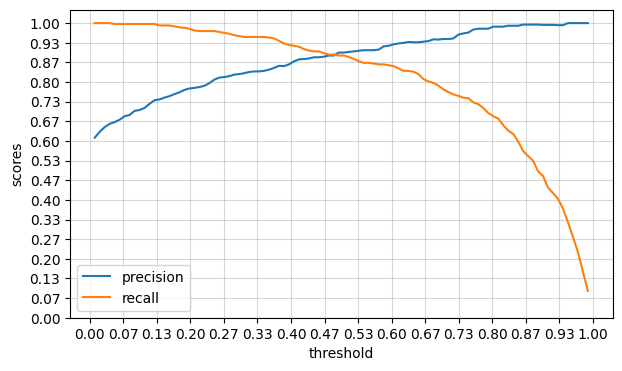

In [341]:
df_score = pd.DataFrame(scores, columns=("thresh", "prec_val", "rec_val"))

plt.figure(figsize=(7, 4))
plt.plot(df_score["thresh"], df_score["prec_val"], label="precision")
plt.plot(df_score["thresh"], df_score["rec_val"], label="recall")
plt.xlabel("threshold")
plt.ylabel("scores")

ticks_positions = [i / 15 for i in range(16)]
plt.xticks(ticks_positions, [f"{t:.2f}" for t in ticks_positions])
plt.yticks(ticks_positions, [f"{t:.2f}" for t in ticks_positions])

plt.legend()
plt.grid(True, alpha=0.5)

`0.48` is the best.

In [337]:
THRESHOLD = 0.48

In [328]:
y_pred_binary = (y_pred >= THRESHOLD).astype(int)

print("roc_auc_score:", round(roc_auc_score(y_test, y_pred), 3))
print("accuracy_score:", round(accuracy_score(y_test, y_pred_binary), 3))
print("recall_score:", round(recall_score(y_test, y_pred_binary), 3))
print("f1_score:", round(f1_score(y_test, y_pred_binary), 3))

roc_auc_score: 0.95
accuracy_score: 0.868
recall_score: 0.893
f1_score: 0.892


### Save full pipeline

In [332]:
import joblib
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Merge train and val dataset to get much data
df_full_train = pd.concat([df_train, df_val])
records_full_train = df_full_train.drop("at_risk", axis=1).to_dict("records")
y_full_train = df_full_train["at_risk"].values

pipeline = Pipeline(
    [
        ("vectorizer", DictVectorizer(sparse=True)),
        ("classifier", XGBClassifier(**xgb_params, n_estimators=100)),
    ]
)

pipeline.fit(records_full_train, y_full_train)

# Save the entire pipeline
joblib.dump(pipeline, "pipeline.bin")

['pipeline.bin']

In [346]:
from sklearn.metrics import precision_score

X_test_records = df_test.drop("at_risk", axis=1).to_dict("records")
y_test = df_test["at_risk"].values

# Predict the probability of burnout, then binarize with the tuned cutoff
y_pred = pipeline.predict_proba(X_test_records)[:, 1]
y_pred_binary = (y_pred >= THRESHOLD).astype(int)

print("\n == Metrics == \n")
print("roc_auc_score:", round(roc_auc_score(y_test, y_pred), 3))
print("accuracy_score:", round(accuracy_score(y_test, y_pred_binary), 3))
print("recall_score:", round(recall_score(y_test, y_pred_binary), 3))
print("precision_score:", round(precision_score(y_test, y_pred_binary), 3))
print()


 == Metrics == 

roc_auc_score: 0.897
accuracy_score: 0.808
recall_score: 0.834
precision_score: 0.846

